Rock-paper-scissors_(paper).png: Rock (99.92%)
Rock-paper-scissors_(rock).png: Rock (100.00%)
Rock-paper-scissors_(scissors).png: Rock (83.92%)


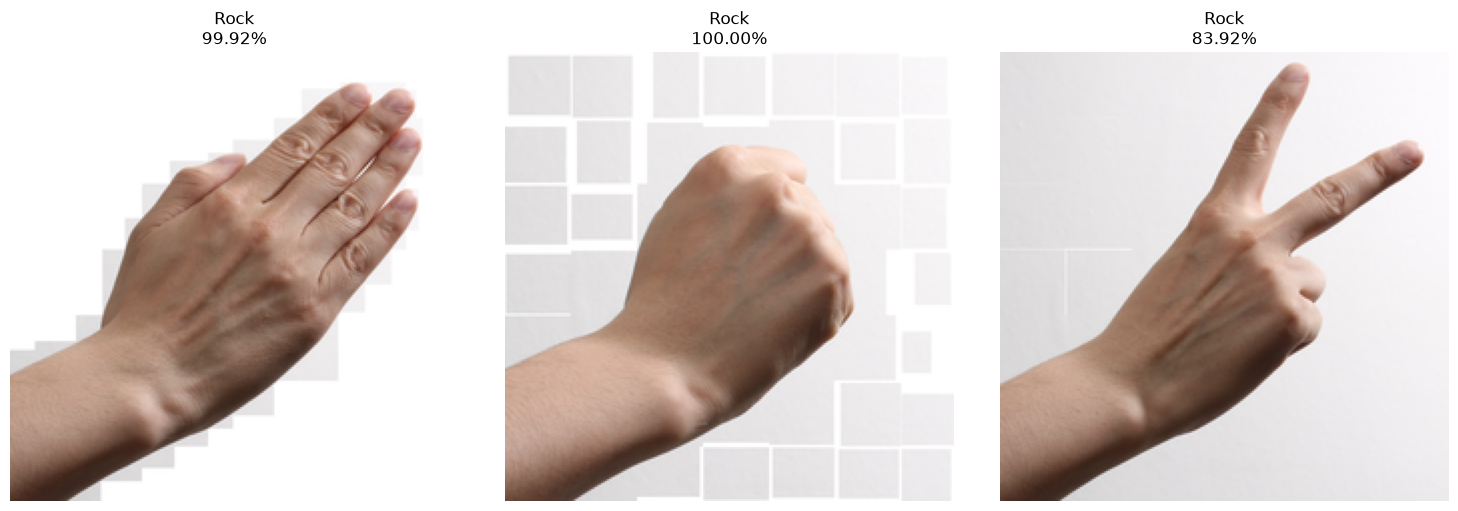

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model and labels
model = load_model("keras_model.h5", compile=False)
class_names = [label.strip().split(" ", 1)[1] for label in open("labels.txt", "r")]

image_paths = sorted(Path(".").glob("*.png"))
figure, axes = plt.subplots(1, len(image_paths), figsize=(15, 5))

if len(image_paths) == 1:
    axes = [axes]

for axis, image_path in zip(axes, image_paths):
    image = Image.open(image_path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)

    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data = np.expand_dims(normalized_image_array, axis=0)

    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction[0])
    class_name = class_names[index]
    confidence_score = prediction[0][index]

    print(f"{image_path.name}: {class_name} ({confidence_score:.2%})")
    axis.imshow(image)
    axis.set_title(f"{class_name}\n{confidence_score:.2%}")
    axis.axis("off")

figure.tight_layout()
plt.show()

# Model is not very good